# 🎓 Analyse statistique du mode de vie étudiant

## Prétraitement et exploration des données

**Problématique :** les habitudes quotidiennes des étudiants sont-elles associées à leur performance académique ?

Ce notebook présente le dataset, vérifie sa qualité, décrit les variables et étudie les relations entre le mode de vie, le stress et le GPA. Il s'agit d'une analyse statistique ; aucun modèle de Machine Learning n'est entraîné ici.

## 1. Importation et chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
DATA_PATH = 'student_lifestyle_dataset.csv'
df = pd.read_csv(DATA_PATH)
print(f'Dimensions : {df.shape[0]} lignes et {df.shape[1]} colonnes')
df.head()

Dimensions : 2000 lignes et 8 colonnes


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


## 2. Description du dataset

Le dataset contient 2 000 étudiants et 8 variables. Les variables horaires représentent le nombre d'heures consacrées chaque jour à différentes activités. `GPA` représente la performance académique et `Stress_Level` le niveau de stress déclaré ou attribué.

In [2]:
df.info()
display(df.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Student_ID                       2000 non-null   int64  
 1   Study_Hours_Per_Day              2000 non-null   float64
 2   Extracurricular_Hours_Per_Day    2000 non-null   float64
 3   Sleep_Hours_Per_Day              2000 non-null   float64
 4   Social_Hours_Per_Day             2000 non-null   float64
 5   Physical_Activity_Hours_Per_Day  2000 non-null   float64
 6   GPA                              2000 non-null   float64
 7   Stress_Level                     2000 non-null   object 
dtypes: float64(6), int64(1), object(1)
memory usage: 125.1+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
Study_Hours_Per_Day,2000.0,NaN,NaN,NaN,7.4758,1.423888,5.0,6.3,7.4,8.7,10.0
Extracurricular_Hours_Per_Day,2000.0,NaN,NaN,NaN,1.9901,1.155855,0.0,1.0,2.0,3.0,4.0
Sleep_Hours_Per_Day,2000.0,NaN,NaN,NaN,7.50125,1.460949,5.0,6.2,7.5,8.8,10.0
Social_Hours_Per_Day,2000.0,NaN,NaN,NaN,2.70455,1.688514,0.0,1.2,2.6,4.1,6.0
Physical_Activity_Hours_Per_Day,2000.0,NaN,NaN,NaN,4.3283,2.51411,0.0,2.4,4.1,6.1,13.0
GPA,2000.0,NaN,NaN,NaN,3.11596,0.298674,2.24,2.9,3.11,3.33,4.0
Stress_Level,2000,3,High,1029,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Qualité des données

Nous vérifions les valeurs manquantes, les doublons, les identifiants et les valeurs possibles des variables catégorielles.

In [3]:
print('Valeurs manquantes par colonne :')
display(df.isna().sum().to_frame('nombre'))
print('Nombre de doublons exacts :', df.duplicated().sum())
print('Identifiants uniques :', df['Student_ID'].nunique())
print('Niveaux de stress :', df['Stress_Level'].unique())

Valeurs manquantes par colonne :


,nombre
Student_ID,0
Study_Hours_Per_Day,0
Extracurricular_Hours_Per_Day,0
Sleep_Hours_Per_Day,0
Social_Hours_Per_Day,0
Physical_Activity_Hours_Per_Day,0
GPA,0
Stress_Level,0


Nombre de doublons exacts : 0
Identifiants uniques : 2000
Niveaux de stress : ['Moderate' 'Low' 'High']


### Première conclusion sur la qualité

Le dataset ne contient aucune valeur manquante ni aucun doublon exact. Il ne nécessite donc pas d'imputation. Cette absence de nettoyage complexe est une caractéristique du dataset et doit être signalée dans la présentation.

## 4. Statistiques descriptives

In [4]:
numeric_cols = ['Study_Hours_Per_Day','Extracurricular_Hours_Per_Day','Sleep_Hours_Per_Day','Social_Hours_Per_Day','Physical_Activity_Hours_Per_Day','GPA']
display(df[numeric_cols].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Study_Hours_Per_Day,2000.0,7.476,1.424,5.00,6.3,7.40,8.70,10.0
Extracurricular_Hours_Per_Day,2000.0,1.990,1.156,0.00,1.0,2.00,3.00,4.0
Sleep_Hours_Per_Day,2000.0,7.501,1.461,5.00,6.2,7.50,8.80,10.0
Social_Hours_Per_Day,2000.0,2.705,1.689,0.00,1.2,2.60,4.10,6.0
Physical_Activity_Hours_Per_Day,2000.0,4.328,2.514,0.00,2.4,4.10,6.10,13.0
GPA,2000.0,3.116,0.299,2.24,2.9,3.11,3.33,4.0


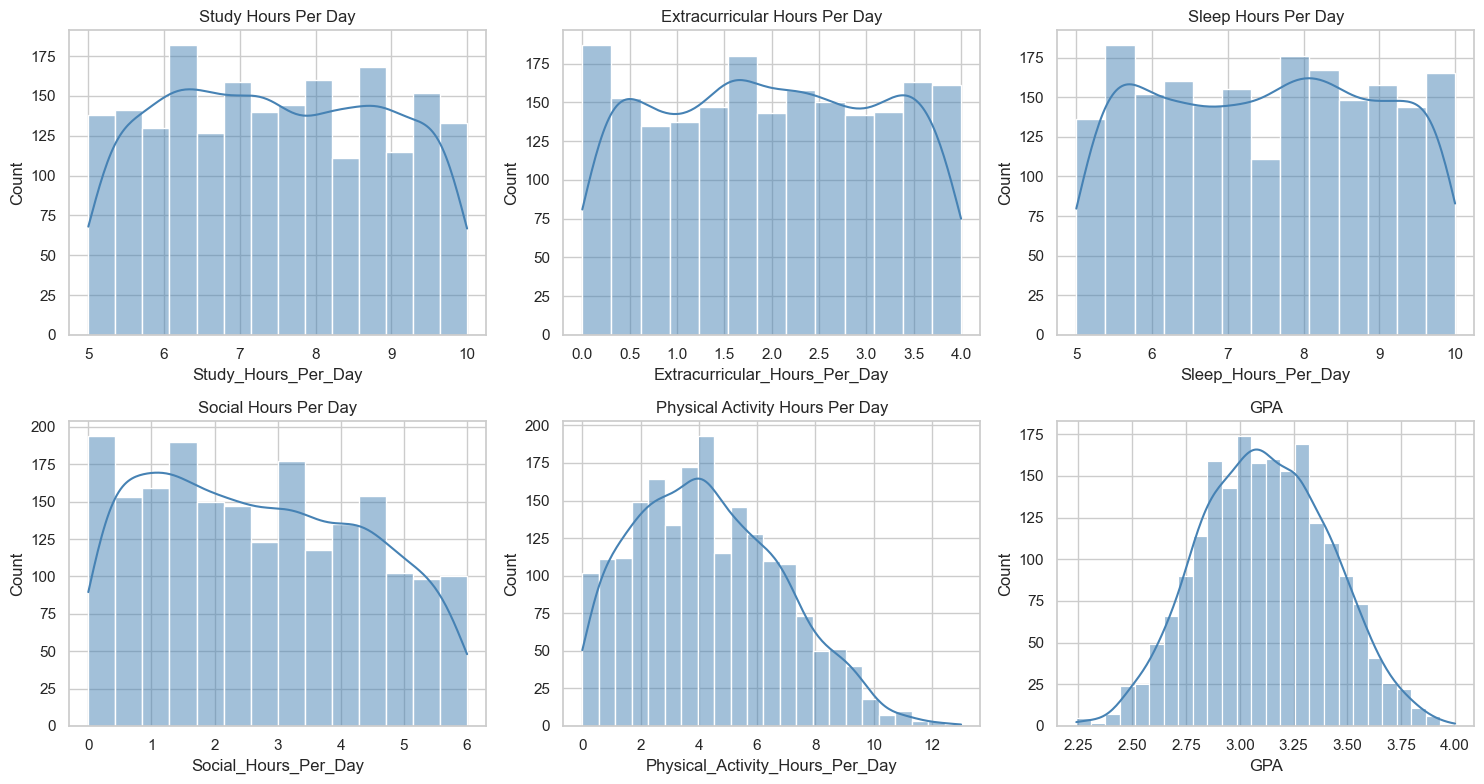

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(col.replace('_',' '))
plt.tight_layout()
plt.show()

Les heures d'étude ont une moyenne de **7,48 heures par jour** et le GPA a une moyenne de **3,12**. Les variables horaires doivent toutefois être interprétées ensemble, car elles décrivent une même journée de 24 heures.

## 5. Vérification de la contrainte des 24 heures

Une question importante est de vérifier si les différentes activités représentent bien une répartition complète de la journée.

In [6]:
time_cols = ['Study_Hours_Per_Day','Extracurricular_Hours_Per_Day','Sleep_Hours_Per_Day','Social_Hours_Per_Day','Physical_Activity_Hours_Per_Day']
df['Total_Hours'] = df[time_cols].sum(axis=1)
display(df['Total_Hours'].describe())
print('Nombre de lignes dont le total est différent de 24 :', (df['Total_Hours'] != 24).sum())

count    2.000000e+03
mean     2.400000e+01
std      1.575252e-15
min      2.400000e+01
25%      2.400000e+01
50%      2.400000e+01
75%      2.400000e+01
max      2.400000e+01
Name: Total_Hours, dtype: float64

Nombre de lignes dont le total est différent de 24 : 393


Le total est égal à 24 heures pour les 2 000 lignes. Cela indique que les variables sont contraintes entre elles. Il faut donc éviter d'interpréter chaque coefficient comme si les autres activités pouvaient rester fixes indépendamment. Cette régularité peut aussi suggérer que le dataset a été construit ou généré selon une règle précise.

## 6. Répartition du niveau de stress

,nombre
Stress_Level,
High,1029
Moderate,674
Low,297


C:\Users\DELL\AppData\Local\Temp\ipykernel_5352\1091828648.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Stress_Level', order=['Low','Moderate','High'], palette='Set2')


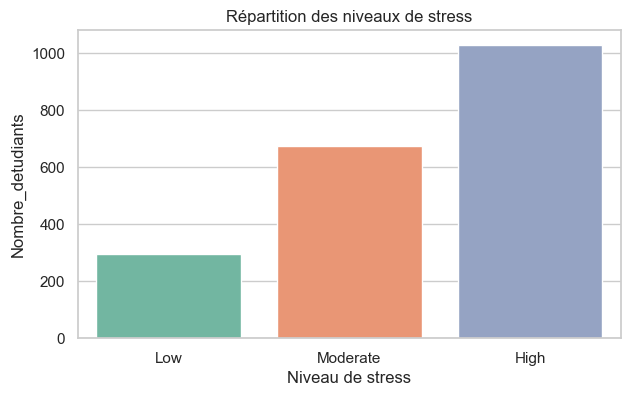

In [7]:
stress_counts = df['Stress_Level'].value_counts()
display(stress_counts.to_frame('nombre'))

plt.figure(figsize=(7,4))
sns.countplot(data=df, x='Stress_Level', order=['Low','Moderate','High'], palette='Set2')
plt.title('Répartition des niveaux de stress')
plt.xlabel('Niveau de stress')
plt.ylabel('Nombre_detudiants')
plt.show()

,count,mean,median,std
Stress_Level,,,,
Low,297,2.817,2.82,0.215
Moderate,674,3.025,3.02,0.221
High,1029,3.262,3.27,0.275


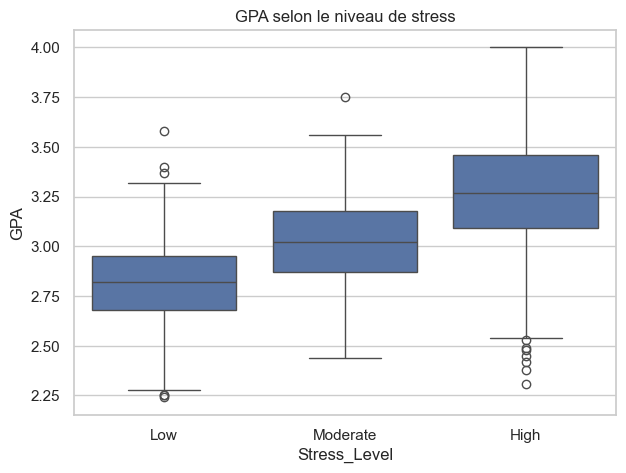

In [8]:
stress_gpa = df.groupby('Stress_Level')['GPA'].agg(['count','mean','median','std']).reindex(['Low','Moderate','High'])
display(stress_gpa.round(3))

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Stress_Level', y='GPA', order=['Low','Moderate','High'])
plt.title('GPA selon le niveau de stress')
plt.show()

Dans cette base, le GPA moyen est de **2,817** pour le niveau de stress faible, **3,025** pour le niveau modéré et **3,262** pour le niveau élevé. Ce résultat est contre-intuitif et ne doit pas être interprété comme une relation causale. Il peut refléter la manière dont le dataset a été construit ou le fait que le niveau de stress n'est pas une mesure indépendante.

## 7. Corrélations avec le GPA

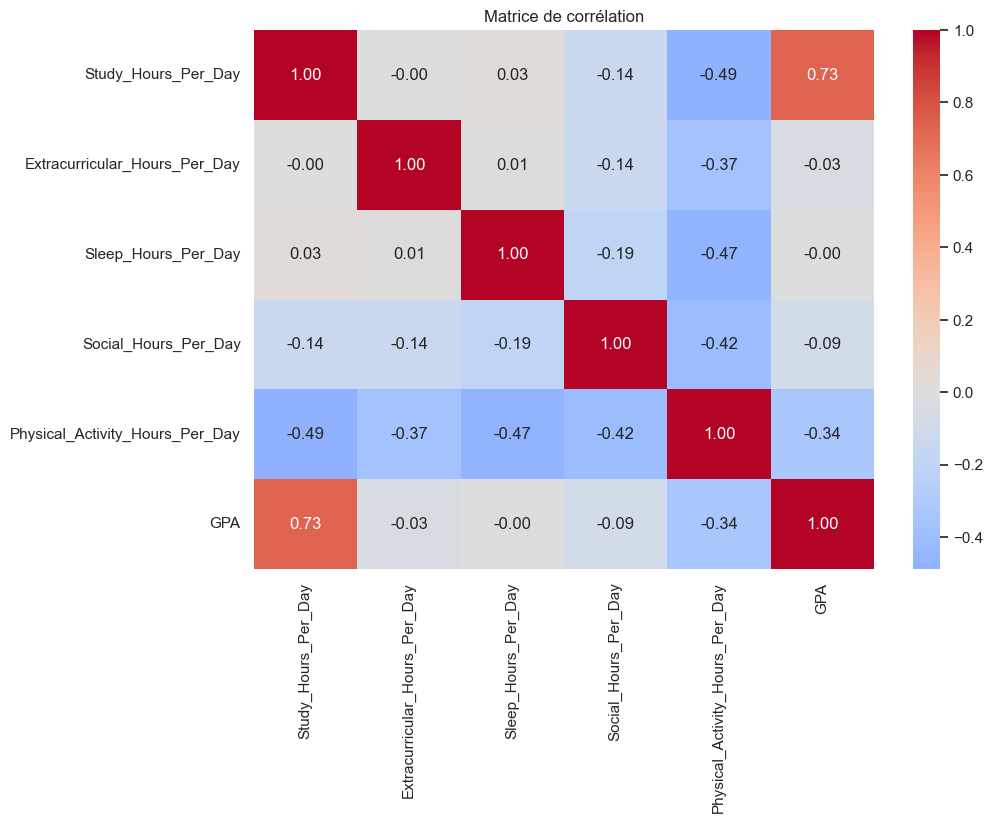

Corrélations avec le GPA :


,corrélation
GPA,1.000
Study_Hours_Per_Day,0.734
Sleep_Hours_Per_Day,-0.004
Extracurricular_Hours_Per_Day,-0.032
Social_Hours_Per_Day,-0.086
Physical_Activity_Hours_Per_Day,-0.341


In [9]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.show()

print('Corrélations avec le GPA :')
display(corr['GPA'].sort_values(ascending=False).to_frame('corrélation').round(3))

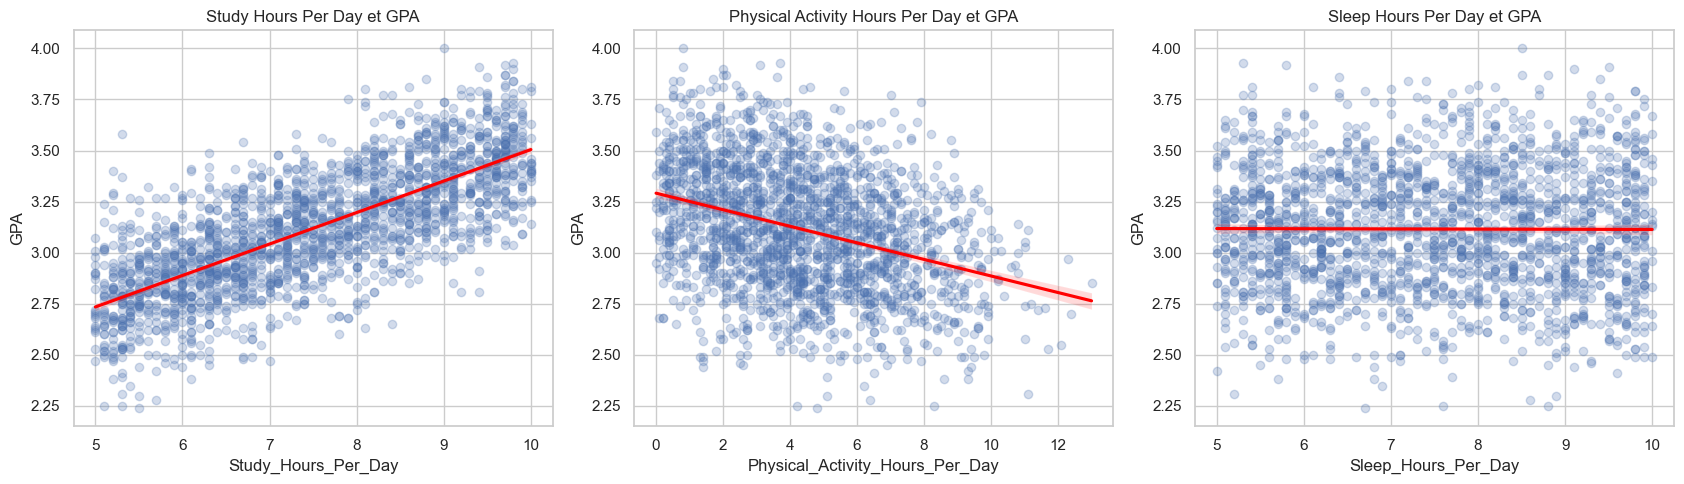

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17,5))
for ax, col in zip(axes, ['Study_Hours_Per_Day','Physical_Activity_Hours_Per_Day','Sleep_Hours_Per_Day']):
    sns.regplot(data=df, x=col, y='GPA', scatter_kws={'alpha':.25}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'{col.replace(chr(95), chr(32))} et GPA')
plt.tight_layout()
plt.show()

La corrélation la plus forte est celle entre les heures d'étude et le GPA, avec environ **0,734**. La corrélation avec l'activité physique est négative, environ **−0,341**. Le sommeil présente une corrélation presque nulle, environ **−0,004**.

Ces résultats montrent des associations, mais ils ne prouvent pas qu'une activité cause directement une hausse ou une baisse du GPA.

## 8. Valeurs aberrantes avec l'IQR

In [11]:
def iqr_report(series):
    q1, q3 = series.quantile([.25,.75])
    iqr = q3-q1
    low, high = q1-1.5*iqr, q3+1.5*iqr
    n = ((series<low)|(series>high)).sum()
    return q1, q3, low, high, n

for col in numeric_cols:
    q1,q3,low,high,n = iqr_report(df[col])
    print(f'{col}: {n} valeur(s) potentiellement aberrante(s), bornes [{low:.2f}, {high:.2f}]')

Study_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [2.70, 12.30]
Extracurricular_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [-2.00, 6.00]
Sleep_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [2.30, 12.70]
Social_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [-3.15, 8.45]
Physical_Activity_Hours_Per_Day: 5 valeur(s) potentiellement aberrante(s), bornes [-3.15, 11.65]
GPA: 4 valeur(s) potentiellement aberrante(s), bornes [2.25, 3.98]


La méthode IQR signale des valeurs potentiellement extrêmes, mais une valeur extrême n'est pas automatiquement une erreur. Nous ne supprimons pas ces observations sans vérifier leur cohérence avec le contexte du dataset.

## 9. Conclusion

Le dataset contient 2 000 étudiants et 8 variables. Il est propre sur le plan technique : aucune valeur manquante et aucun doublon exact. Il est donc plus simple à analyser que le dataset de ventes de jeux vidéo.

L'analyse met en évidence une forte association entre les heures d'étude et le GPA. L'activité physique présente une association négative modérée, tandis que le sommeil et les activités extrascolaires ont des corrélations faibles avec le GPA.

Cependant, les résultats doivent être interprétés avec prudence. Les cinq variables horaires totalisent exactement 24 heures pour chaque étudiant, et la relation entre stress et GPA est contre-intuitive. Ces éléments suggèrent que les données peuvent avoir été construites selon des règles artificielles.

Ce dataset convient donc pour apprendre et présenter les outils statistiques, mais il ne permet pas nécessairement de tirer des conclusions générales sur tous les étudiants. Une étape de Machine Learning pourrait être envisagée plus tard, après vérification de la documentation et de la construction des variables.